# NewsRetrieval — Recuperación de información en noticias

Práctica académica completa sobre un corpus fijo de 2,000 noticias en inglés. Se comparan doce representaciones VSM mediante quince consultas y cinco métricas. La referencia de 303 qrels está congelada para **evaluación analítica delegada**; este alcance no equivale a aprobación humana institucional exhaustiva.


## 1. Introducción

El sistema combina dos campos (título/cuerpo), unigramas o bigramas y tres ponderaciones (frecuencia, binaria y TF-IDF). Las consultas se normalizan como los documentos y los resultados se ordenan por similitud coseno. El notebook reutiliza el corpus y las matrices persistidas: no descarga noticias ni reconstruye vectores.


In [1]:
from collections import Counter
from datetime import datetime
from hashlib import sha256
from html import escape
from pathlib import Path
import csv, json, math, platform

import joblib, spacy, sklearn
from IPython.display import HTML, Markdown, SVG, display
from sklearn.metrics.pairwise import cosine_similarity

from collector import FEEDS, read_corpus, validate_corpus
from evaluation import (CONFIGURATIONS, MAIN_CONFIGURATION, METRICS, calculate_metrics,
                        evaluate, load_benchmark, validate_benchmark)
from retrieval import STOP_POS, clean_text, load_nlp, normalize_text, search_news

def find_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate/'data/news_raw_corpus.tsv').exists() and (candidate/'retrieval.py').exists():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del proyecto')

ROOT=find_root(); DATA=ROOT/'data'; RESULTS=ROOT/'results'; VECTORS=RESULTS/'vectors.joblib'

def read_tsv(path, comments=False):
    with Path(path).open(encoding='utf-8-sig', newline='') as stream:
        lines=(line for line in stream if not(comments and line.startswith('#')))
        return list(csv.DictReader(lines, delimiter='\t'))

def hash_file(path):
    value=sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''): value.update(block)
    return value.hexdigest()

def table(rows, columns=None, limit=20, title=''):
    rows=list(rows); columns=columns or (list(rows[0]) if rows else []); shown=rows[:limit]
    def fmt(value): return f'{value:.6f}' if isinstance(value,float) else str(value)
    head=''.join(f'<th>{escape(str(column))}</th>' for column in columns)
    body=''.join('<tr>'+''.join(f'<td>{escape(fmt(row.get(column,"")))}</td>' for column in columns)+'</tr>' for row in shown)
    caption=f'<caption><strong>{escape(title)}</strong></caption>' if title else ''
    note=f'<p><em>Se muestran {len(shown)} de {len(rows)} filas.</em></p>' if len(shown)<len(rows) else ''
    display(HTML(f'<table>{caption}<thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>{note}'))

versions=[{'componente':'Python','versión':platform.python_version()},
          {'componente':'spaCy','versión':spacy.__version__},
          {'componente':'modelo en_core_web_sm','versión':load_nlp().meta['version']},
          {'componente':'scikit-learn','versión':sklearn.__version__},
          {'componente':'joblib','versión':joblib.__version__}]
display(Markdown(f'**Rutas del proyecto:** relativas a `./` — **ejecución:** {datetime.now().isoformat(timespec="seconds")}'))
table(versions,title='Entorno utilizado')


**Rutas del proyecto:** relativas a `./` — **ejecución:** 2026-10-23T10:17:02

componente,versión
Python,3.11.5
spaCy,3.8.5
modelo en_core_web_sm,3.8.0
scikit-learn,1.6.1
joblib,1.5.0


## 2. Extracción de noticias

La adquisición original utilizó la API de MediaWiki para Wikinews y feeds RSS/Atom para Global Voices y EFF. Se aplicaron validación, deduplicación, atribución y escritura atómica. Aquí se carga el corpus persistido y se muestran registros auténticos.


In [2]:
raw=read_corpus(DATA/'news_raw_corpus.tsv'); normalized=read_tsv(DATA/'news_normalized_corpus.tsv')
validate_corpus(raw)
assert len(raw)==len(normalized)==2000
assert [row['id'] for row in raw]==[row['id'] for row in normalized]
sources=Counter(row['source'] for row in raw); categories=Counter(row['category'] for row in raw)
dates=[row['date'] for row in raw]
summary=[{'indicador':'Noticias','valor':len(raw)}, {'indicador':'IDs únicos','valor':len({r['id'] for r in raw})},
         {'indicador':'Fuentes','valor':dict(sources)}, {'indicador':'Categorías','valor':dict(categories)},
         {'indicador':'Fechas','valor':f'{min(dates)} — {max(dates)}'}]
table(summary,title='Corpus fijo')
examples=[]
for source in sorted(sources):
    row=next(item for item in raw if item['source']==source)
    examples.append({'id':row['id'],'fuente':source,'categoría':row['category'],'fecha':row['date'],
                     'título':row['title'],'cuerpo':row['description/body'][:300]+'…','autor':row['author'],
                     'licencia':row['license'],'URL':row['url']})
table(examples,limit=3,title='Ejemplos originales y atribución')
table([{'fuente':'Wikinews','mecanismo':'API MediaWiki; texto introductorio de páginas inglesas'},
       {'fuente':'Global Voices','mecanismo':'feeds RSS/Atom temáticos'},
       {'fuente':'EFF','mecanismo':'feed Deeplinks; exclusión de republicaciones de terceros'}],
      title='Procedencia y mecanismo de extracción')


indicador,valor
Noticias,2000
IDs únicos,2000
Fuentes,"{'EFF': 39, 'Global Voices': 180, 'Wikinews': 1781}"
Categorías,"{'tecnologia': 666, 'finanzas': 667, 'deportes': 667}"
Fechas,2004-11-16 — 2026-10-16


id,fuente,categoría,fecha,título,cuerpo,autor,licencia,URL
Nb52ef31d6f481a85dba5,EFF,tecnologia,2026-10-16,In Memoriam: Barry Steinhardt,"Barry Steinhardt, a lifelong privacy champion and an early leader in the battle for digital civil liberties who served as EFF’s president in 1998-99, died last week at age 73. A Connecticut native, Steinhardt led the Vermont and Pennsylvania affiliates of the American Civil Liberties Union before be…",Josh Richman,CC BY 4.0 (texto original EFF; sin bloques citados),https://www.eff.org/deeplinks/2026/10/memoriam-barry-steinhardt
N8002e77bdcfaa28419f1,Global Voices,tecnologia,2026-10-15,How authoritarian states are building an international market for digital surveillance,"Digital authoritarianism is not developing in isolation, but through the international exchange of technologies, standards, and practices.…",Daria Dergacheva,CC BY 3.0 (resumen de Global Voices),https://globalvoices.org/2026/10/15/how-authoritarian-states-are-building-an-international-market-for-digital-surveillance
N4403486b4323214767d6,Wikinews,deportes,2026-03-18,Caloundra win round 3 game in Australian soccer's Football Queensland Premier League 2 competition,"Caloundra have won their round 3 Football Queensland Premier League 2 game against Pine Hills 5 goals to 2 at Meridan Plains, Queensland, Australia on Sunday. ""Two from three "" said Caloundra captain Kaine Frew. ""I think we'll probably be in the top four now. Not a bad start. It's still very early d…",Wikinews,CC BY 4.0 (Wikinews),https://en.wikinews.org/wiki/Caloundra_win_round_3_game_in_Australian_soccer%27s_Football_Queensland_Premier_League_2_competition


fuente,mecanismo
Wikinews,API MediaWiki; texto introductorio de páginas inglesas
Global Voices,feeds RSS/Atom temáticos
EFF,feed Deeplinks; exclusión de republicaciones de terceros


## 3. Normalización

El proceso real incluye limpieza, tokenización, POS tagging, eliminación selectiva de palabras funcionales, lematización y unión con espacios simples. Título y cuerpo se normalizan por separado.


In [3]:
sample=next(row for row in raw if len(row['description/body'].split())>=100)
persisted=next(row for row in normalized if row['id']==sample['id'])
doc=load_nlp()(clean_text(sample['title']+' '+sample['description/body']))
def decision(token):
    lemma=token.lemma_.lower().strip()
    if token.is_space:return 'eliminar: espacio'
    if token.is_punct:return 'eliminar: puntuación'
    if token.tag_=='POS' or lemma in {"'s",'’s'}:return 'eliminar: posesivo'
    if not any(ch.isalnum() for ch in lemma):return 'eliminar: no alfanumérico'
    if token.is_stop and token.pos_ in STOP_POS:return 'eliminar: palabra funcional/POS'
    if token.is_stop and token.tag_=='DT' and token.lower_ in {'a','an','the'}:return 'eliminar: artículo'
    return 'conservar'
token_trace=[{'token':t.text,'POS':t.pos_,'tag':t.tag_,'lema':t.lemma_.lower().strip(),'decisión':decision(t)} for t in doc[:50]]
display(Markdown(f"**Noticia:** `{sample['id']}` — {sample['title']}"))
table(token_trace,limit=50,title='Tokenización, POS, lema y filtrado')
assert normalize_text(sample['title'])==persisted['normalized_title']
assert normalize_text(sample['description/body'])==persisted['normalized_body']
table([{'campo':'título','original':sample['title'],'normalizado':persisted['normalized_title']},
       {'campo':'cuerpo','original':sample['description/body'][:450]+'…','normalizado':persisted['normalized_body'][:450]+'…'}],
      title='Texto original y normalizado')


**Noticia:** `Nb52ef31d6f481a85dba5` — In Memoriam: Barry Steinhardt

token,POS,tag,lema,decisión
In,ADP,IN,in,eliminar: palabra funcional/POS
Memoriam,PROPN,NNP,memoriam,conservar
:,PUNCT,:,:,eliminar: puntuación
Barry,PROPN,NNP,barry,conservar
Steinhardt,PROPN,NNP,steinhardt,conservar
Barry,PROPN,NNP,barry,conservar
Steinhardt,PROPN,NNP,steinhardt,conservar
",",PUNCT,",",",",eliminar: puntuación
a,DET,DT,a,eliminar: artículo
lifelong,ADJ,JJ,lifelong,conservar


campo,original,normalizado
título,In Memoriam: Barry Steinhardt,memoriam barry steinhardt
cuerpo,"Barry Steinhardt, a lifelong privacy champion and an early leader in the battle for digital civil liberties who served as EFF’s president in 1998-99, died last week at age 73. A Connecticut native, Steinhardt led the Vermont and Pennsylvania affiliates of the American Civil Liberties Union before becoming associate director of the national ACLU. There, he helped spearhead the fight to overturn much of the Communications Decency Act, resulting in …",barry steinhardt lifelong privacy champion early leader battle digital civil liberty serve eff president 1998 99 die last week age 73 connecticut native steinhardt lead vermont pennsylvania affiliate american civil liberties union become associate director national aclu there help spearhead fight to overturn much communications decency act result u.s. supreme court landmark reno v. aclu rule 1997 internet be still young steinhardt become one firs…


## 4. Representaciones vectoriales

Se cargan las doce matrices CSR persistidas. Cada configuración posee su propio vectorizador y vocabulario. Los valores siguientes pertenecen a la noticia mostrada en la sección anterior.


In [4]:
bundle=joblib.load(VECTORS); assert len(bundle['spaces'])==12 and len(bundle['ids'])==2000
sample_index=bundle['ids'].index(sample['id']); spaces=[]
for key,space in bundle['spaces'].items():
    vector=space['matrix'].getrow(sample_index); names=space['vectorizer'].get_feature_names_out()
    pairs=sorted(((names[i],float(v)) for i,v in zip(vector.indices,vector.data)),key=lambda x:(-x[1],x[0]))[:5]
    field,ngram,weight=key.split('_',2)
    spaces.append({'configuración':key,'campo':field,'n-grama':ngram,'ponderación':weight,
                   'dimensiones':str(space['matrix'].shape),'vocabulario':len(names),'no nulos':vector.nnz,
                   'características y valores':'; '.join(f'{term}={value:.4f}' for term,value in pairs)})
table(spaces,limit=12,title='Las doce matrices VSM')

frequency=bundle['spaces']['body_1_frequency']; tfidf=bundle['spaces']['body_1_tfidf']
terms=frequency['vectorizer'].get_feature_names_out(); fv=frequency['matrix'].getrow(sample_index)
tv=tfidf['matrix'].getrow(sample_index); fdict=dict(zip(fv.indices,fv.data)); tdict=dict(zip(tv.indices,tv.data))
illustration=[]
for index,count in sorted(fdict.items(),key=lambda x:(-x[1],terms[x[0]]))[:12]:
    illustration.append({'término':terms[index],'frecuencia':int(count),'TF-IDF':float(tdict.get(index,0.0))})
table(illustration,limit=12,title='Frecuencia y TF-IDF de términos reales del cuerpo')


configuración,campo,n-grama,ponderación,dimensiones,vocabulario,no nulos,características y valores
title_1_frequency,title,1,frequency,"(2000, 4761)",4761,3,barry=1.0000; memoriam=1.0000; steinhardt=1.0000
title_1_binary,title,1,binary,"(2000, 4761)",4761,3,barry=1.0000; memoriam=1.0000; steinhardt=1.0000
title_1_tfidf,title,1,tfidf,"(2000, 4761)",4761,3,memoriam=0.5996; steinhardt=0.5996; barry=0.5301
title_2_frequency,title,2,frequency,"(2000, 11371)",11371,2,barry steinhardt=1.0000; memoriam barry=1.0000
title_2_binary,title,2,binary,"(2000, 11371)",11371,2,barry steinhardt=1.0000; memoriam barry=1.0000
title_2_tfidf,title,2,tfidf,"(2000, 11371)",11371,2,barry steinhardt=0.7071; memoriam barry=0.7071
body_1_frequency,body,1,frequency,"(2000, 28211)",28211,149,aclu=6.0000; privacy=5.0000; to=5.0000; be=4.0000; steinhardt=4.0000
body_1_binary,body,1,binary,"(2000, 28211)",28211,149,1997=1.0000; 1998=1.0000; 1999=1.0000; 2002=1.0000; 2003=1.0000
body_1_tfidf,body,1,tfidf,"(2000, 28211)",28211,149,aclu=0.4222; steinhardt=0.3413; privacy=0.2440; barry=0.2039; liberty=0.2039
body_2_frequency,body,2,frequency,"(2000, 281386)",281386,198,civil liberty=2.0000; eff president=2.0000; 1997 internet=1.0000; 1998 99=1.0000; 1998 take=1.0000


término,frecuencia,TF-IDF
aclu,6,0.422155
privacy,5,0.244018
to,5,0.061696
be,4,0.046189
steinhardt,4,0.341258
barry,3,0.203856
become,3,0.097672
civil,3,0.155178
conference,3,0.124253
eff,3,0.156649


## 5. Recuperación paso a paso

Se demuestra una consulta real con la configuración principal: normalización, vectorización, coseno, ordenamiento y Top-10.


In [5]:
queries=read_tsv(DATA/'queries.tsv'); demo_query=queries[0]; space=bundle['spaces'][MAIN_CONFIGURATION]
normalized_query=normalize_text(demo_query['query']); query_vector=space['vectorizer'].transform([normalized_query])
scores=cosine_similarity(query_vector,space['matrix']).ravel(); order=sorted(range(len(scores)),key=lambda i:(-scores[i],i))[:10]
retrieved=search_news(demo_query['query'],'body',1,'tfidf',bundle=bundle)
assert [row['id'] for row in retrieved]==[bundle['ids'][i] for i in order]
display(Markdown(f"**Consulta original:** {demo_query['query']}  \n**Consulta normalizada:** `{normalized_query}`  \n"
                 f"**Vector:** {query_vector.shape[1]} dimensiones, {query_vector.nnz} valores no nulos.  \n"
                 "**Similitud:** producto coseno entre el vector de consulta y cada fila; orden descendente con desempate estable."))
table([{'rank':rank,'id':row['id'],'título':row['title'],'score':row['score'],'URL':row['url']} for rank,row in enumerate(retrieved,1)],
      limit=10,title='Diez documentos recuperados')


**Consulta original:** trade agreements, negotiations, and disputes between countries or economic blocs  
**Consulta normalizada:** `trade agreement negotiation dispute country economic bloc`  
**Vector:** 28211 dimensiones, 7 valores no nulos.  
**Similitud:** producto coseno entre el vector de consulta y cada fila; orden descendente con desempate estable.

rank,id,título,score,URL
1,Nd00f4a574528048de1f5,Doha round of trade talks suspended after negotiations fail,0.239594,https://en.wikinews.org/wiki/Doha_round_of_trade_talks_suspended_after_negotiations_fail
2,N8b562e211fd1319d7225,"Benin, Nigeria join African Union continental free trade bloc",0.225379,"https://en.wikinews.org/wiki/Benin,_Nigeria_join_African_Union_continental_free_trade_bloc"
3,N051030b00da79066a62d,"'Each makes the other more difficult to recover from': University of Sussex professor L. Alan Winters speaks to Wikinews on trade, COVID-19, Brexit",0.215570,"https://en.wikinews.org/wiki/%27Each_makes_the_other_more_difficult_to_recover_from%27:_University_of_Sussex_professor_L._Alan_Winters_speaks_to_Wikinews_on_trade,_COVID-19,_Brexit"
4,N2d3a1cef5cea1361fb72,Doha round negotiations might restart in a matter of weeks,0.204402,https://en.wikinews.org/wiki/Doha_round_negotiations_might_restart_in_a_matter_of_weeks
5,N3f28c2427d7287bd37fd,Australia exports less to US despite FTA,0.184507,https://en.wikinews.org/wiki/Australia_exports_less_to_US_despite_FTA
6,N0b7dca731a735582ed42,Economy - Bush toughens up on Central America,0.169070,https://en.wikinews.org/wiki/Economy_-_Bush_toughens_up_on_Central_America
7,Nb744e63b1da77bec8d89,Colombia signs FTA with Mercosur,0.146340,https://en.wikinews.org/wiki/Colombia_signs_FTA_with_Mercosur
8,Nc8ef11b54b1451d86839,India and U.S.A. work toward nuclear fuel agreement,0.132720,https://en.wikinews.org/wiki/India_and_U.S.A._work_toward_nuclear_fuel_agreement
9,N0cc74978d10832ae9b08,CAFTA faces tough vote in U.S. House,0.128644,https://en.wikinews.org/wiki/CAFTA_faces_tough_vote_in_U.S._House
10,N330790994f262b4d1217,"EU, China fail to agree on textile trade",0.128623,"https://en.wikinews.org/wiki/EU,_China_fail_to_agree_on_textile_trade"


## 6. Relevancia de los resultados

`show_top10(query_id, configuration)` permite inspeccionar cualquiera de las 180 combinaciones. Distingue grados 0, 1 y 2, muestra el estado de juicio y resume aciertos. La similitud solo determina el orden; nunca la etiqueta.


In [6]:
judgment_rows=read_tsv(RESULTS/'retrieval_judgments.tsv')
def show_top10(query_id, configuration):
    rows=[row for row in judgment_rows if row['query_id']==query_id and row['configuration']==configuration]
    rows.sort(key=lambda row:int(row['rank']))
    if len(rows)!=10: raise ValueError('La selección no contiene exactamente diez resultados')
    shown=[{'Rank':int(row['rank']),'Documento':f"{row['document_id']} — {row['title']}",
            'Similitud':float(row['score']),'Relevancia':int(row['relevance_grade']),
            '¿Correcto?':'sí' if row['is_relevant']=='1' else 'no','Estado':row['judgment_status']} for row in rows]
    relevant=sum(row['is_relevant']=='1' for row in rows); irrelevant=10-relevant
    table(shown,limit=10,title=f'{query_id} / {configuration}')
    display(Markdown(f'**Resumen:** 10 noticias devueltas; {relevant} relevantes; {irrelevant} irrelevantes; '
                     f'Precision@10 = {relevant}/10 = {relevant/10:.2f}.'))
    return rows

demo_rows=show_top10('Q01',MAIN_CONFIGURATION)


Rank,Documento,Similitud,Relevancia,¿Correcto?,Estado
1,Nd00f4a574528048de1f5 — Doha round of trade talks suspended after negotiations fail,0.239594,2,sí,aceptada_revision_analitica_delegada
2,"N8b562e211fd1319d7225 — Benin, Nigeria join African Union continental free trade bloc",0.225379,2,sí,aceptada_revision_analitica_delegada
3,"N051030b00da79066a62d — 'Each makes the other more difficult to recover from': University of Sussex professor L. Alan Winters speaks to Wikinews on trade, COVID-19, Brexit",0.215570,2,sí,aceptada_revision_analitica_delegada
4,N2d3a1cef5cea1361fb72 — Doha round negotiations might restart in a matter of weeks,0.204402,2,sí,aceptada_revision_analitica_delegada
5,N3f28c2427d7287bd37fd — Australia exports less to US despite FTA,0.184507,1,sí,aceptada_revision_analitica_delegada
6,N0b7dca731a735582ed42 — Economy - Bush toughens up on Central America,0.169070,2,sí,aceptada_revision_analitica_delegada
7,Nb744e63b1da77bec8d89 — Colombia signs FTA with Mercosur,0.146340,2,sí,aceptada_revision_analitica_delegada
8,Nc8ef11b54b1451d86839 — India and U.S.A. work toward nuclear fuel agreement,0.132720,2,sí,aceptada_revision_analitica_delegada
9,N0cc74978d10832ae9b08 — CAFTA faces tough vote in U.S. House,0.128644,2,sí,aceptada_revision_analitica_delegada
10,"N330790994f262b4d1217 — EU, China fail to agree on textile trade",0.128623,2,sí,aceptada_revision_analitica_delegada


**Resumen:** 10 noticias devueltas; 10 relevantes; 0 irrelevantes; Precision@10 = 10/10 = 1.00.

## 7. Benchmark

Las quince consultas corresponden a cinco necesidades y tres dificultades. Los 303 qrels contienen únicamente positivos 1 y 2. Los negativos confirmados se conservan en la tabla consolidada de adjudicación.

La referencia supera el máximo literal de 15 en comercio, fútbol y vigilancia. Se conserva completa para no ocultar positivos ni reducir artificialmente el denominador de Recall. El núcleo académico es solo expositivo.


In [7]:
benchmark_queries,qrels=load_benchmark(DATA/'queries.tsv',DATA/'qrels.tsv')
validation=validate_benchmark(benchmark_queries,qrels,raw)
status=read_tsv(DATA/'benchmark_status.tsv'); freeze=json.loads((DATA/'reference_freeze_record.json').read_text(encoding='utf-8'))
query_table=[{**row,'positivos':len(qrels[row['query_id']]),
              'grado 1':sum(v==1 for v in qrels[row['query_id']].values()),
              'grado 2':sum(v==2 for v in qrels[row['query_id']].values())} for row in benchmark_queries]
table(status,title='Estado y alcance de validación')
table(query_table,limit=15,title='Consultas, dificultades y referencia completa')
table([{'control':'qrels congelados','valor':sum(len(v) for v in qrels.values())},
       {'control':'SHA-256 qrels','valor':freeze['frozen_qrels_sha256']},
       {'control':'consultas por dificultad','valor':validation['difficulty_levels']},
       {'control':'máximo académico superado','valor':validation['academic_range_exceeded']}],title='Controles del benchmark')


C:\Users\salaz\AppData\Local\Temp\ipykernel_22660\2521195168.py:2: UserWarning: Referencia ampliada: se conservan positivos auténticos por encima del intervalo académico de 10-15: {'Q01': 28, 'Q02': 28, 'Q03': 28, 'Q07': 20, 'Q08': 20, 'Q09': 20, 'Q13': 25, 'Q14': 25, 'Q15': 25}
  validation=validate_benchmark(benchmark_queries,qrels,raw)


artifact,status,approval_scope,note
qrels.tsv,frozen_delegated_analytical_validation,accepted_for_delegated_analytical_evaluation_not_institutional_human_approval,"Referencia ampliada de 303 qrels congelada. Supera 15 positivos en comercio, fútbol y vigilancia para no ocultar documentos relevantes; academic_reference_core.tsv es solo expositivo."


query_id,difficulty_level,query,positivos,grado 1,grado 2
Q01,1,"trade agreements, negotiations, and disputes between countries or economic blocs",28,10,18
Q02,2,"government-to-government commerce pacts, treaty approval, and cross-border tariff conflicts",28,10,18
Q03,3,"how states negotiate, implement, or contest rules governing international exchange",28,10,18
Q04,1,"rising electricity, gas, and fuel bills affecting households, consumers, or businesses",14,3,11
Q05,2,higher energy charges and fuel costs creating pressure for users and economic activity,14,3,11
Q06,3,how an increase in the cost of power or transport fuel affects everyday and commercial life,14,3,11
Q07,1,"football events linked to political, diplomatic, social, or cultural controversy",20,4,16
Q08,2,"soccer players, teams, or matches involved in public identity, rights, or government issues",20,4,16
Q09,3,how the beautiful game becomes part of conflicts and debates beyond sport,20,4,16
Q10,1,"cricket controversies, discipline, safety, governance, and political disputes",14,8,6


control,valor
qrels congelados,303
SHA-256 qrels,513e85157843888076332b50b70d265942f5853224ee56d23ba1466ebb402a59
consultas por dificultad,"{'1': 5, '2': 5, '3': 5}"
máximo académico superado,"{'Q01': 28, 'Q02': 28, 'Q03': 28, 'Q07': 20, 'Q08': 20, 'Q09': 20, 'Q13': 25, 'Q14': 25, 'Q15': 25}"


## 8. Cálculo de las cinco métricas

Para la combinación demostrativa se reconstruyen las métricas directamente desde los diez grados. Precision usa diez como denominador; Recall usa todos los positivos de la referencia completa; F1 es la media armónica; MRR usa el primer positivo; nDCG emplea ganancia `2^rel - 1` y descuento `log2(rank+1)`.


In [8]:
demo_grades=[int(row['relevance_grade']) for row in demo_rows]
hits=sum(grade>0 for grade in demo_grades); total=len(qrels['Q01'])
precision=hits/10; recall=hits/total; f1=2*precision*recall/(precision+recall) if precision+recall else 0
first=next((rank for rank,grade in enumerate(demo_grades,1) if grade>0),0); mrr=1/first if first else 0
dcg_parts=[(2**grade-1)/math.log2(rank+1) for rank,grade in enumerate(demo_grades,1)]
ideal=sorted(qrels['Q01'].values(),reverse=True)[:10]
idcg_parts=[(2**grade-1)/math.log2(rank+1) for rank,grade in enumerate(ideal,1)]
ndcg=sum(dcg_parts)/sum(idcg_parts)
library=calculate_metrics([{'id':row['document_id']} for row in demo_rows],qrels['Q01'])
manual={'precision@10':precision,'recall@10':recall,'f1@10':f1,'mrr':mrr,'ndcg@10':ndcg}
assert all(abs(manual[key]-library[key])<1e-12 for key in METRICS)
table([{'métrica':'Precision@10','conteo/fórmula':f'{hits}/10','resultado':precision},
       {'métrica':'Recall@10','conteo/fórmula':f'{hits}/{total}','resultado':recall},
       {'métrica':'F1@10','conteo/fórmula':'2PR/(P+R)','resultado':f1},
       {'métrica':'MRR','conteo/fórmula':f'1/{first}' if first else '0','resultado':mrr},
       {'métrica':'nDCG@10','conteo/fórmula':f'{sum(dcg_parts):.6f}/{sum(idcg_parts):.6f}','resultado':ndcg}],
      title='Derivación desde los diez juicios reales')
table([{'rank':rank,'grado':grade,'ganancia':2**grade-1,'aporte_DCG':dcg_parts[rank-1]} for rank,grade in enumerate(demo_grades,1)],
      limit=10,title='Ganancia graduada y descuento por posición')


métrica,conteo/fórmula,resultado
Precision@10,10/10,1.000000
Recall@10,10/28,0.357143
F1@10,2PR/(P+R),0.526316
MRR,1/1,1.000000
nDCG@10,12.856972/13.630678,0.943238


rank,grado,ganancia,aporte_DCG
1,2,3,3.000000
2,2,3,1.892789
3,2,3,1.500000
4,2,3,1.292030
5,1,1,0.386853
6,2,3,1.068622
7,2,3,1.000000
8,2,3,0.946395
9,2,3,0.903090
10,2,3,0.867194


## 9. Evaluación de las 180 combinaciones

La celda ejecuta nuevamente la evaluación congelada, verifica que el hash de qrels no cambie y reconstruye todos los resultados finales. Cada configuración aporta 150 devoluciones.


In [9]:
qrels_hash_before=hash_file(DATA/'qrels.tsv')
run=evaluate(benchmark_queries,qrels,bundle=bundle,output_dir=RESULTS,frozen=True)
assert hash_file(DATA/'qrels.tsv')==qrels_hash_before
assert run['evaluations']==180 and run['rankings_all']==1800 and run['unjudged']==0
metrics_rows=read_tsv(RESULTS/'metrics_by_query_configuration.tsv'); comparison=read_tsv(RESULTS/'comparison.tsv')
means=[row for row in comparison if row['difficulty_level']=='all']
table(means,limit=12,title='Resultados finales por configuración (15 consultas)')
display(Markdown(f"**Ejecución:** {run['evaluations']} evaluaciones, {run['rankings_all']} devoluciones, "
                 f"{run['zero_similarity_results']} con score cero y {run['unjudged']} sin juicio."))


configuration,difficulty_level,query_count,retrieved_results,relevant_retrieved,irrelevant_retrieved,unjudged_retrieved,zero_similarity_results,precision@10,recall@10,f1@10,mrr,ndcg@10
title_1_frequency,all,15,150,24,126,0,0,0.16,0.08923809523809524,0.11260651629072684,0.5462962962962962,0.17168167947524587
title_1_binary,all,15,150,30,120,0,0,0.19999999999999998,0.11142857142857142,0.14086048454469507,0.5272222222222223,0.19510018444836588
title_1_tfidf,all,15,150,19,131,0,0,0.1266666666666667,0.0641904761904762,0.08359231411862991,0.44222222222222224,0.15525834839404115
title_2_frequency,all,15,150,21,129,0,146,0.14,0.058761904761904765,0.08238095238095239,0.26666666666666666,0.14572814887294322
title_2_binary,all,15,150,21,129,0,146,0.14,0.058761904761904765,0.08238095238095239,0.26666666666666666,0.14572814887294322
title_2_tfidf,all,15,150,21,129,0,146,0.14,0.058761904761904765,0.08238095238095239,0.26666666666666666,0.14572814887294322
body_1_frequency,all,15,150,36,114,0,0,0.24000000000000007,0.12657142857142858,0.16223057644110275,0.5677777777777778,0.2776860470033269
body_1_binary,all,15,150,37,113,0,0,0.24666666666666665,0.13628571428571426,0.17233918128654968,0.5416666666666666,0.2550229741186448
body_1_tfidf,all,15,150,48,102,0,0,0.31999999999999995,0.1726666666666667,0.21956558061821213,0.5762962962962964,0.334886059588326
body_2_frequency,all,15,150,30,120,0,74,0.2,0.09000000000000001,0.12205513784461153,0.24722222222222223,0.16554456543315768


**Ejecución:** 180 evaluaciones, 1800 devoluciones, 660 con score cero y 0 sin juicio.

## 10. Gráficas comparativas

Las gráficas SVG proceden de la misma ejecución: desempeño de las doce configuraciones, dificultad, precisión/recall, positivos recuperados y resultados con coincidencia léxica nula.


**01 ndcg by configuration**

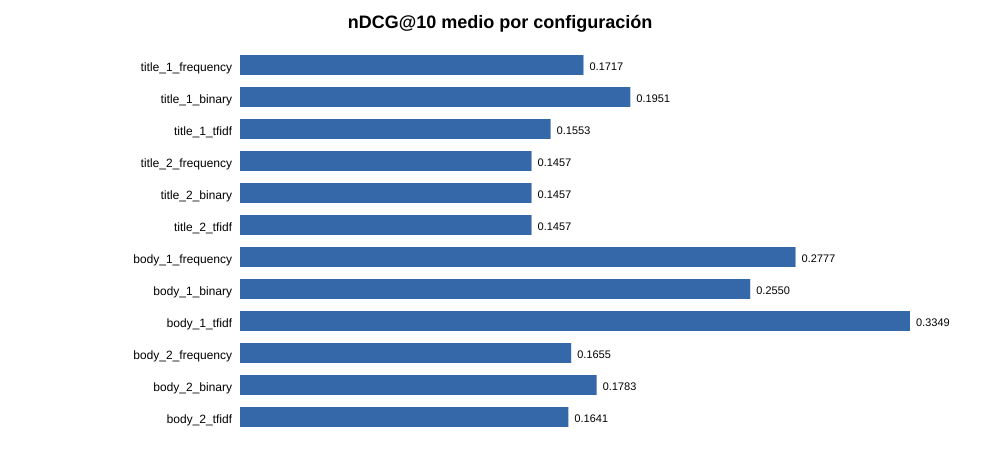

**02 relevant returns by configuration**

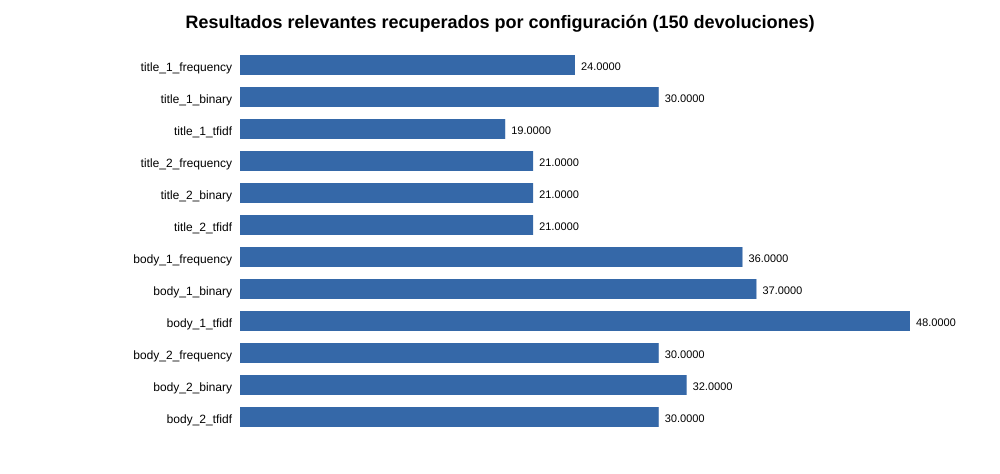

**03 zero similarity by configuration**

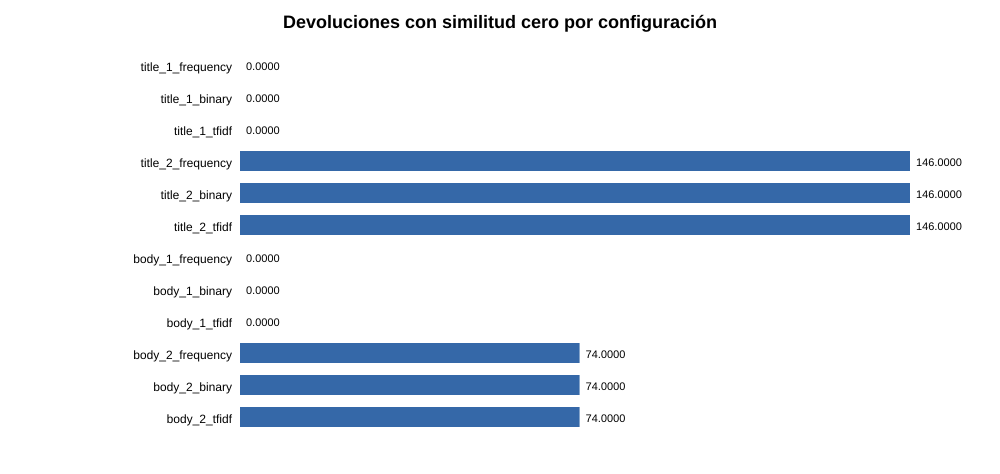

**04 ndcg by difficulty**

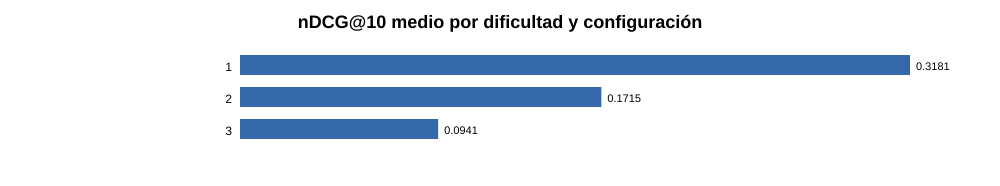

**05 precision recall by configuration**

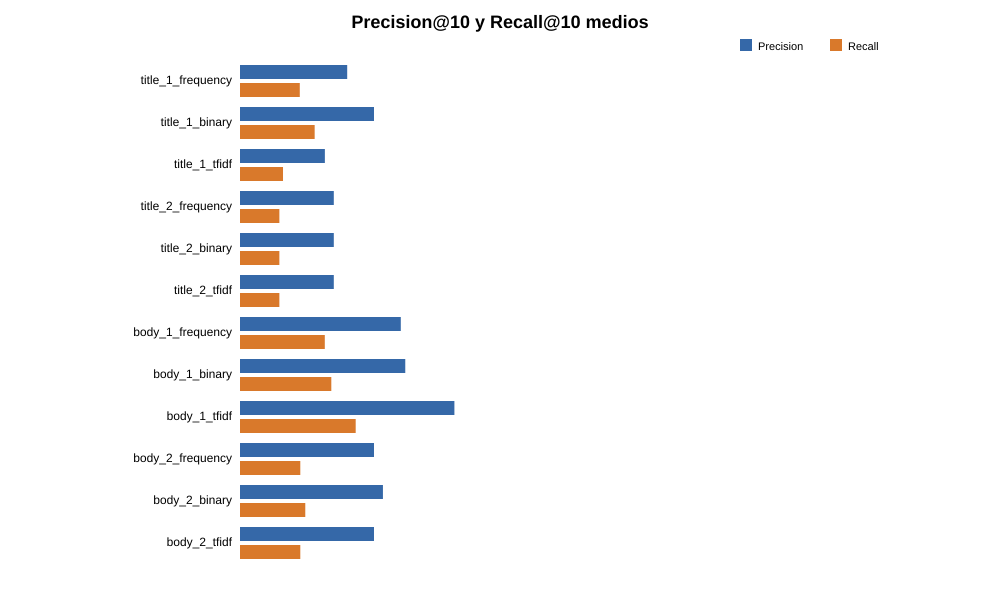

In [10]:
for filename in ['01_ndcg_by_configuration.svg','02_relevant_returns_by_configuration.svg',
                 '03_zero_similarity_by_configuration.svg','04_ndcg_by_difficulty.svg',
                 '05_precision_recall_by_configuration.svg']:
    display(Markdown(f'**{filename[:-4].replace("_"," ")}**'))
    display(SVG(filename=str(RESULTS/'figures'/filename)))


## 11. Análisis de errores

La selección primaria utiliza `body_1_tfidf`. Se muestran cinco consultas con mayor y cinco con menor nDCG@10, evidencia observable y comparación con las otras configuraciones. Los indicadores léxicos permiten formular hipótesis, pero no prueban causalidad por sí solos.


In [11]:
for row in metrics_rows:
    for key in [*METRICS,'score']:
        if key in row and row[key]!='': row[key]=float(row[key])
primary=sorted((row for row in metrics_rows if row['configuration']==MAIN_CONFIGURATION),
               key=lambda row:(row['ndcg@10'],row['mrr'],row['query_id']))
selected=primary[:5]+list(reversed(primary[-5:])); vocabulary=set(bundle['spaces'][MAIN_CONFIGURATION]['vectorizer'].get_feature_names_out())
diagnosis=[]
for metric in selected:
    query=next(row for row in queries if row['query_id']==metric['query_id']); tokens=normalize_text(query['query']).split()
    oov=[token for token in tokens if token not in vocabulary]
    rows=[row for row in judgment_rows if row['query_id']==metric['query_id'] and row['configuration']==MAIN_CONFIGURATION]
    zero=sum(row['zero_similarity']=='1' for row in rows)
    observation=(f"{metric['relevant_retrieved']} positivos en Top-10; cobertura léxica {len(tokens)-len(oov)}/{len(tokens)}; "
                 f"{zero} scores cero"+(f"; OOV: {', '.join(oov)}" if oov else ''))
    hypothesis='Revisar sinónimos, paráfrasis y ambigüedad' if metric['precision@10']==0 or oov else 'La evidencia no permite atribuir una causa única'
    diagnosis.append({'grupo':'peor' if metric in primary[:5] else 'mejor','consulta':metric['query_id'],
                      'nDCG@10':metric['ndcg@10'],'P@10':metric['precision@10'],'R@10':metric['recall@10'],
                      'observación demostrada':observation,'posible explicación':hypothesis,
                      'primer título':rows[0]['title']})
table(diagnosis,limit=10,title='Cinco mejores y cinco peores en la configuración principal')

cross=[]
for metric in selected:
    rows=[row for row in metrics_rows if row['query_id']==metric['query_id']]
    best=max(rows,key=lambda row:(row['ndcg@10'],row['mrr'],row['configuration']))
    worst=min(rows,key=lambda row:(row['ndcg@10'],row['mrr'],row['configuration']))
    cross.append({'consulta':metric['query_id'],'principal nDCG':metric['ndcg@10'],
                  'mejor configuración':best['configuration'],'mejor nDCG':best['ndcg@10'],
                  'peor configuración':worst['configuration'],'peor nDCG':worst['ndcg@10']})
table(cross,limit=10,title='Comparación con las restantes configuraciones')


grupo,consulta,nDCG@10,P@10,R@10,observación demostrada,posible explicación,primer título
peor,Q03,0.000000,0.000000,0.000000,0 positivos en Top-10; cobertura léxica 8/8; 0 scores cero,"Revisar sinónimos, paráfrasis y ambigüedad",How authoritarian states are building an international market for digital surveillance
peor,Q09,0.000000,0.000000,0.000000,0 positivos en Top-10; cobertura léxica 7/7; 0 scores cero,"Revisar sinónimos, paráfrasis y ambigüedad",Australian sport may be on the cusp of change
peor,Q15,0.066254,0.100000,0.040000,1 positivos en Top-10; cobertura léxica 9/9; 0 scores cero,La evidencia no permite atribuir una causa única,Clinical signs a 'reliable measure' of HIV treatment progress
peor,Q12,0.119543,0.200000,0.142857,2 positivos en Top-10; cobertura léxica 8/8; 0 scores cero,La evidencia no permite atribuir una causa única,Bangladesh’s energy crisis worsens as US's war on Iran drags on
peor,Q08,0.138862,0.100000,0.050000,1 positivos en Top-10; cobertura léxica 10/10; 0 scores cero,La evidencia no permite atribuir una causa única,Abby Wambach wins FIFA World Player of the Year
mejor,Q01,0.943238,1.000000,0.357143,10 positivos en Top-10; cobertura léxica 7/7; 0 scores cero,La evidencia no permite atribuir una causa única,Doha round of trade talks suspended after negotiations fail
mejor,Q04,0.680450,0.600000,0.428571,6 positivos en Top-10; cobertura léxica 9/9; 0 scores cero,La evidencia no permite atribuir una causa única,Nepal becomes South Asia's priciest place to fill a tank as US war on Iran rattles the pump
mejor,Q06,0.503324,0.400000,0.285714,4 positivos en Top-10; cobertura léxica 9/9; 0 scores cero,La evidencia no permite atribuir una causa única,Nepal becomes South Asia's priciest place to fill a tank as US war on Iran rattles the pump
mejor,Q13,0.495094,0.500000,0.200000,5 positivos en Top-10; cobertura léxica 6/6; 0 scores cero,La evidencia no permite atribuir una causa única,In Memoriam: Barry Steinhardt
mejor,Q10,0.450803,0.300000,0.214286,3 positivos en Top-10; cobertura léxica 7/7; 0 scores cero,La evidencia no permite atribuir una causa única,Pitching power: Unpacking the T20 Cricket World Cup crisis between Bangladesh and India


consulta,principal nDCG,mejor configuración,mejor nDCG,peor configuración,peor nDCG
Q03,0.000000,body_1_binary,0.138862,body_1_tfidf,0.000000
Q09,0.000000,title_1_binary,0.133052,body_1_binary,0.000000
Q15,0.066254,title_2_tfidf,0.580602,body_1_tfidf,0.066254
Q12,0.119543,title_1_binary,0.178305,body_1_binary,0.000000
Q08,0.138862,title_1_frequency,0.305235,body_2_binary,0.000000
Q01,0.943238,body_1_tfidf,0.943238,title_2_binary,0.000000
Q04,0.680450,body_1_binary,0.772160,title_2_binary,0.220092
Q06,0.503324,body_1_tfidf,0.503324,body_2_binary,0.000000
Q13,0.495094,title_2_tfidf,0.580602,title_1_binary,0.110046
Q10,0.450803,body_1_tfidf,0.450803,body_2_binary,0.000000


## 12. Conclusiones y reproducibilidad

Las conclusiones se derivan de las métricas observadas, sin imponer a priori una ponderación ganadora. El sistema conserva corpus, qrels y matrices mediante hashes; las pruebas comprueban fórmulas e invariantes.


In [12]:
numeric=[{**row,**{key:float(row[key]) for key in METRICS}} for row in means]
best=[]
for metric in METRICS:
    row=max(numeric,key=lambda item:(item[metric],item['configuration']))
    best.append({'métrica':metric,'mejor configuración':row['configuration'],'valor':row[metric]})
table(best,title='Mejor configuración observada por métrica')
integrity=[{'archivo':str(path.relative_to(ROOT)).replace('\\','/'),'bytes':path.stat().st_size,'SHA-256':hash_file(path)} for path in
           [DATA/'news_raw_corpus.tsv',DATA/'news_normalized_corpus.tsv',VECTORS,DATA/'queries.tsv',DATA/'qrels.tsv',
            RESULTS/'rankings_all_configurations.tsv',RESULTS/'retrieval_judgments.tsv',RESULTS/'metrics_by_query_configuration.tsv']]
table(integrity,limit=20,title='Integridad de artefactos esenciales')
display(Markdown('**Ejecución reproducible:** `python -m unittest -v test_project` y `python main.py --benchmark --frozen`.  \n'
                 '**Limitaciones:** validación analítica delegada; pool no exhaustivo; sensibilidad léxica a sinónimos, paráfrasis, '
                 'ambigüedad, nombres propios y extractos; empates con similitud cero conservados y juzgados.'))


métrica,mejor configuración,valor
precision@10,body_1_tfidf,0.320000
recall@10,body_1_tfidf,0.172667
f1@10,body_1_tfidf,0.219566
mrr,body_1_tfidf,0.576296
ndcg@10,body_1_tfidf,0.334886


archivo,bytes,SHA-256
data/news_raw_corpus.tsv,4428783,82ea7d58c1a457f8bf23822735e5b4d41354fad0b7b82bd929b769017ebc1f6f
data/news_normalized_corpus.tsv,7391814,1793f6b542452c58a612ad3177054bd331f2198afc8bff1c12d7d808465342b8
results/vectors.joblib,54609343,181c2e77f18759c80274b48e319c3f2680a1d3fcab52135f37be547ca4c3d76c
data/queries.tsv,1356,04a9b3fe41c6dab7ce9f65f76380e345d6765c0fcca99a9a1b84eefc85850cfd
data/qrels.tsv,8515,513e85157843888076332b50b70d265942f5853224ee56d23ba1466ebb402a59
results/rankings_all_configurations.tsv,589585,007915a276d485bd29e26a983304878256e3f3e68e6b9b26495072988d15e845
results/retrieval_judgments.tsv,1125376,7a8830fcc0b01836f8501fea5c0969fe4f75c247914910caa2f107a27263dfc0
results/metrics_by_query_configuration.tsv,17038,fd4e0dd66661acd784710340d85e250fcfea5c6af97590cd55fa90b25b19a83e


**Ejecución reproducible:** `python -m unittest -v test_project` y `python main.py --benchmark --frozen`.  
**Limitaciones:** validación analítica delegada; pool no exhaustivo; sensibilidad léxica a sinónimos, paráfrasis, ambigüedad, nombres propios y extractos; empates con similitud cero conservados y juzgados.